# Lab L5-2：模型怎麼「寫」出一封回覆？迷你 GPT（D5-2）

**需求單 #D5-2**（虛構公司：曜嶼電子，客服中心）：把回覆交給模型寫之前，主管要先懂它怎麼「寫」。

| 部分 | 做什麼 | 輸出 |
|---|---|---|
| 1 | 真的小模型（Qwen2.5-0.5B）：下一個 token 的前 10 名；溫度怎麼改變機率 | 長條圖 |
| 2 | 自己組一個迷你字元 GPT：注意力頭（含 causal mask）→ 多頭 → Transformer 區塊 | 形狀檢查 |
| 3 | 在 5,606 封合成繁中客服回覆上訓練（next-token cross-entropy） | loss 曲線 |
| 4 | 取樣：溫度、top-k、top-p | 樣本表 |
| 5 | KV cache：同一個模型，開／關快取的生成速度 | 秒數 |

執行階段：**T4 GPU**（訓練時間待講師 T4 實測；講師本機 CPU 2000 步約 13 分鐘）。沒有 GPU：`TRAIN = False` 直接載入講師的權重。

In [51]:
# 第 1 格：環境
import math, time, os, platform, glob, subprocess, urllib.request
import numpy as np
import matplotlib.pyplot as plt
import torch, torch.nn as nn, torch.nn.functional as F
import transformers
from matplotlib import font_manager
NOTO = "/usr/share/fonts/opentype/noto/NotoSansCJK-Regular.ttc"
if not glob.glob(NOTO) and platform.system() == "Linux":
    subprocess.run("apt-get -qq install -y fonts-noto-cjk > /dev/null", shell=True)
for f in glob.glob(NOTO):
    font_manager.fontManager.addfont(f)
    plt.rcParams["font.family"] = font_manager.FontProperties(fname=f).get_name()
print("torch", torch.__version__, "| transformers", transformers.__version__, "| python", platform.python_version())
device = "cuda" if torch.cuda.is_available() else "cpu"
if device == "cuda":
    free, total = torch.cuda.mem_get_info()
    print("GPU:", torch.cuda.get_device_name(0), f"| 可用 VRAM {free/1e9:.1f} / {total/1e9:.1f} GB")
SEED = 0
torch.manual_seed(SEED)

RAW = "https://raw.githubusercontent.com/LinTzuYu0925/GAI_tutorial/day5-done/18-mini-gpt/materials/data"
def fetch(name):
    """下載課程資料到目前資料夾（已下載就不重抓）"""
    local = os.environ.get("LAB_DATA_DIR")          # 只有講師本機測試會設定
    if local:
        return os.path.join(local, name)
    path = os.path.join("data/download", name)
    if not os.path.exists(path):
        os.makedirs("data/download", exist_ok=True)
        urllib.request.urlretrieve(f"{RAW}/{name}", path)
    return path

torch 2.14.1+cu130 | transformers 5.24.1 | python 3.13.16
GPU: Tesla T4 | 可用 VRAM 6.5 / 15.6 GB


## 1. 真的小模型：下一個 token 的前 10 名
「寫字」＝預測下一個 token、選一個、接上去，再預測下一個（D1-2 的文字接龍）。
先看一個真實的 0.5B 開放模型，在一句客服回覆後面，覺得下一個 token 是什麼。

Loading weights:   0%|          | 0/290 [00:00<?, ?it/s]

'可以'       0.214
'需要'       0.063
'的'        0.037
'應該'       0.036
'會'        0.024
'先'        0.019
'來'        0.017
'要'        0.014
'已經'       0.013
'現在'       0.012


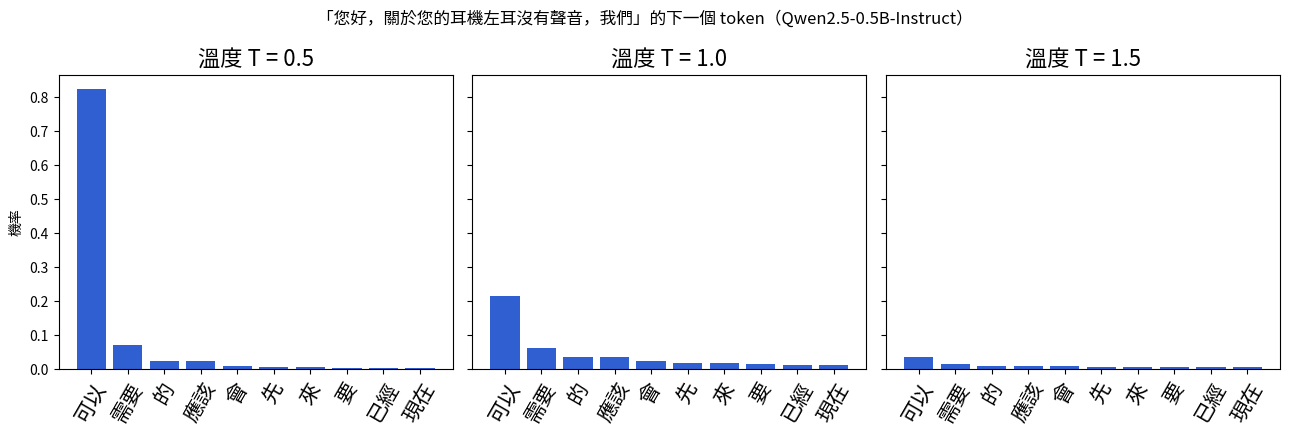

In [52]:
from transformers import AutoTokenizer, AutoModelForCausalLM
QWEN = "Qwen/Qwen2.5-0.5B-Instruct"
qtok = AutoTokenizer.from_pretrained(QWEN)
qwen = AutoModelForCausalLM.from_pretrained(QWEN, dtype=torch.float16 if device == "cuda" else torch.float32).to(device).eval()
PROMPT = "您好，關於您的耳機左耳沒有聲音，我們"
ids = qtok(PROMPT, return_tensors="pt").to(device)
with torch.no_grad():
    logits = qwen(**ids).logits[0, -1].float()       # 最後一個位置：下一個 token 的分數（logits）
probs = torch.softmax(logits, dim=-1)
top = torch.topk(probs, 10)
words = [qtok.decode([i]) for i in top.indices.tolist()]
for w, p in zip(words, top.values.tolist()):
    print(f"{w!r:10s} {p:.3f}")

def bars_at(T):
    """同一組 logits，除以溫度 T 再 softmax：前 10 名的機率"""
    return torch.softmax(logits / T, dim=-1)[top.indices].cpu().numpy()

fig, axes = plt.subplots(1, 3, figsize=(13, 4.4), sharey=True)
for ax, T in zip(axes, [0.5, 1.0, 1.5]):
    ax.bar(range(10), bars_at(T), color="#2f5fd0")
    ax.set_xticks(range(10), words, rotation=60, fontsize=15); ax.set_title(f"溫度 T = {T}", fontsize=16)
axes[0].set_ylabel("機率")
plt.suptitle(f"「{PROMPT}」的下一個 token（Qwen2.5-0.5B-Instruct）"); plt.tight_layout()
plt.savefig("qwen_next_token.png", dpi=150); plt.show()

## 2. 自己組一個迷你 GPT（字元層級）
資料：5,606 封**合成**繁中客服回覆（課程用模板產生，沒有真實資料）。每個字就是一個 token。

In [53]:
text = open(fetch("replies.txt"), encoding="utf-8").read()
chars = sorted(set(text))
VOCAB = len(chars)
stoi = {c: i for i, c in enumerate(chars)}
itos = {i: c for c, i in stoi.items()}
encode = lambda s: [stoi[c] for c in s]
decode = lambda l: "".join(itos[i] for i in l)
data = torch.tensor(encode(text), dtype=torch.long)
n = int(0.9 * len(data))
train_data, val_data = data[:n], data[n:]
print(f"{len(text):,} 個字、{VOCAB} 種字（含換行）；訓練 {n:,}、驗證 {len(data)-n:,}")

BLOCK = 64      # 一次看幾個字（context 長度）
BATCH = 64
def get_batch(split):
    d = train_data if split == "train" else val_data
    ix = torch.randint(len(d) - BLOCK - 1, (BATCH,))
    x = torch.stack([d[i:i + BLOCK] for i in ix])
    y = torch.stack([d[i + 1:i + BLOCK + 1] for i in ix])   # 答案＝往右移一格：每個位置都要猜「下一個字」
    return x.to(device), y.to(device)

xb, yb = get_batch("train")
print("x:", tuple(xb.shape), "y:", tuple(yb.shape))
print("輸入：", decode(xb[0, :20].tolist()))
print("答案：", decode(yb[0, :20].tolist()))

466,986 個字、339 種字（含換行）；訓練 420,287、驗證 46,699
x: (64, 64) y: (64, 64)
輸入： 定已經幫您更正，下一期帳單就會生效。我們
答案： 已經幫您更正，下一期帳單就會生效。我們已


In [54]:
N_EMBD, N_HEAD, N_LAYER, DROPOUT = 128, 4, 4, 0.1

USE_MASK = True    # 只有第 4 部分的「拿掉遮罩」實驗會暫時改成 False

class Head(nn.Module):
    """一個注意力頭：D5-1 的 attention()，加上 causal mask（不准偷看後面）"""
    def __init__(self, head_size):
        super().__init__()
        self.key = nn.Linear(N_EMBD, head_size, bias=False)
        self.query = nn.Linear(N_EMBD, head_size, bias=False)
        self.value = nn.Linear(N_EMBD, head_size, bias=False)
        self.register_buffer("tril", torch.tril(torch.ones(BLOCK, BLOCK)))   # 下三角：1＝可以看
        self.drop = nn.Dropout(DROPOUT)

    def forward(self, x):                     # x: [B, T, C]
        B, T, C = x.shape
        q, k, v = self.query(x), self.key(x), self.value(x)        # 各 [B, T, hs]
        att = q @ k.transpose(-2, -1) / math.sqrt(k.shape[-1])      # [B, T, T]
        if USE_MASK:
            att = att.masked_fill(self.tril[:T, :T] == 0, float("-inf"))
        att = self.drop(torch.softmax(att, dim=-1))
        return att @ v                        # [B, T, hs]

class MultiHead(nn.Module):
    """多頭：幾個頭各自查表、接起來、再混合一次"""
    def __init__(self):
        super().__init__()
        hs = N_EMBD // N_HEAD
        self.heads = nn.ModuleList([Head(hs) for _ in range(N_HEAD)])
        self.proj = nn.Linear(N_EMBD, N_EMBD)
    def forward(self, x):
        return self.proj(torch.cat([h(x) for h in self.heads], dim=-1))

class Block(nn.Module):
    """Transformer 區塊：LayerNorm → 多頭注意力 → 加回去；LayerNorm → 前饋網路 → 加回去"""
    def __init__(self):
        super().__init__()
        self.ln1, self.ln2 = nn.LayerNorm(N_EMBD), nn.LayerNorm(N_EMBD)
        self.attn = MultiHead()
        self.ffwd = nn.Sequential(nn.Linear(N_EMBD, 4 * N_EMBD), nn.GELU(), nn.Linear(4 * N_EMBD, N_EMBD), nn.Dropout(DROPOUT))
    def forward(self, x):
        x = x + self.attn(self.ln1(x))        # 殘差：原本的 x 加上「注意力看到的東西」
        x = x + self.ffwd(self.ln2(x))        # 殘差：再加上「每個字自己想一想」
        return x

def sinusoidal(T, C):
    """正弦位置編碼：和 D3-3 的時間嵌入同一個公式，只是「第幾步」換成「第幾個字」"""
    pos = torch.arange(T).float()[:, None]
    i = torch.arange(0, C, 2).float()[None, :]
    ang = pos / (10000 ** (i / C))
    pe = torch.zeros(T, C)
    pe[:, 0::2], pe[:, 1::2] = torch.sin(ang), torch.cos(ang)
    return pe

class MiniGPT(nn.Module):
    def __init__(self):
        super().__init__()
        self.tok = nn.Embedding(VOCAB, N_EMBD)                         # 查表（D5-1）
        self.register_buffer("pos", sinusoidal(BLOCK, N_EMBD))
        self.blocks = nn.Sequential(*[Block() for _ in range(N_LAYER)])
        self.ln_f = nn.LayerNorm(N_EMBD)
        self.head = nn.Linear(N_EMBD, VOCAB)                            # 每個位置：下一個字的分數
    def forward(self, idx, targets=None):
        B, T = idx.shape
        x = self.tok(idx) + self.pos[:T]                                # [B, T, C]
        logits = self.head(self.ln_f(self.blocks(x)))                   # [B, T, VOCAB]
        loss = None if targets is None else F.cross_entropy(logits.view(-1, VOCAB), targets.view(-1))
        return logits, loss

model = MiniGPT().to(device)
print(f"參數 {sum(p.numel() for p in model.parameters()):,}")
with torch.no_grad():
    lg, ls = model(xb, yb)
print("輸入", tuple(xb.shape), "→ logits", tuple(lg.shape))
print(f"還沒訓練的 loss：{ls.item():.3f}；全部亂猜（每個字機率一樣）會是 ln({VOCAB}) = {math.log(VOCAB):.3f}")

參數 878,931
輸入 (64, 64) → logits (64, 64, 339)
還沒訓練的 loss：6.023；全部亂猜（每個字機率一樣）會是 ln(339) = 5.826


## 3. 訓練：next-token cross-entropy
每個位置都在考「下一個字是什麼」。loss＝正確答案的機率取 −log：
讓正確答案的機率越大越好，這就是**最大概似**（maximum likelihood）。

step     0 | train 6.031 | val 6.030 | 1s
step   100 | train 0.360 | val 0.362 | 5s
step   200 | train 0.204 | val 0.204 | 9s
step   300 | train 0.193 | val 0.192 | 13s
step   400 | train 0.187 | val 0.187 | 18s
step   500 | train 0.186 | val 0.184 | 22s
step   600 | train 0.179 | val 0.180 | 26s
step   700 | train 0.179 | val 0.183 | 31s
step   800 | train 0.179 | val 0.179 | 35s
step   900 | train 0.175 | val 0.179 | 39s
step  1000 | train 0.174 | val 0.177 | 44s
step  1100 | train 0.178 | val 0.179 | 48s
step  1200 | train 0.175 | val 0.177 | 52s
step  1300 | train 0.175 | val 0.177 | 56s
step  1400 | train 0.173 | val 0.175 | 60s
step  1500 | train 0.175 | val 0.178 | 65s
step  1600 | train 0.174 | val 0.173 | 70s
step  1700 | train 0.173 | val 0.172 | 74s
step  1800 | train 0.171 | val 0.172 | 79s
step  1900 | train 0.173 | val 0.174 | 84s
step  2000 | train 0.170 | val 0.176 | 88s
訓練 2000 步，88 秒
VRAM 峰值 8.02 GB


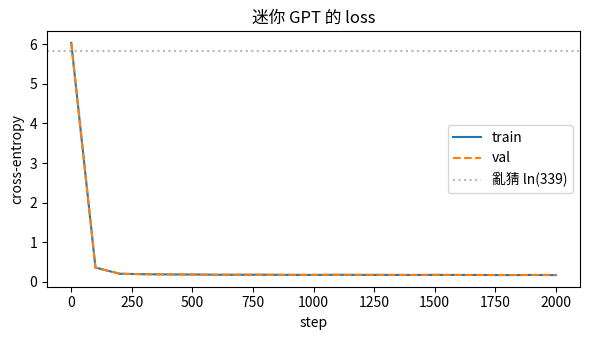

In [55]:
TRAIN = True       # 沒有 GPU 或想省時間：改成 False，直接載入講師訓練好的權重
STEPS = 2000 if device == "cuda" else 300
LR = 1e-3

@torch.no_grad()
def estimate(split, iters=20):
    model.eval()
    l = torch.stack([model(*get_batch(split))[1] for _ in range(iters)]).mean().item()
    model.train()
    return l

if TRAIN:
    opt = torch.optim.AdamW(model.parameters(), lr=LR)
    hist, t0 = [], time.time()
    if device == "cuda":
        torch.cuda.reset_peak_memory_stats()
    for step in range(STEPS + 1):
        if step % 100 == 0:
            tr, va = estimate("train"), estimate("val")
            hist.append((step, tr, va))
            print(f"step {step:5d} | train {tr:.3f} | val {va:.3f} | {time.time()-t0:.0f}s")
        if step == STEPS:
            break
        x, y = get_batch("train")
        _, loss = model(x, y)
        opt.zero_grad(set_to_none=True)
        loss.backward()
        opt.step()
    print(f"訓練 {STEPS} 步，{time.time()-t0:.0f} 秒")
    if device == "cuda":
        print(f"VRAM 峰值 {torch.cuda.max_memory_allocated()/1e9:.2f} GB")
    torch.save(model.state_dict(), "minigpt.pt")
    s, tr, va = zip(*hist)
    plt.figure(figsize=(6, 3.5))
    plt.plot(s, tr, label="train"); plt.plot(s, va, "--", label="val")
    plt.axhline(math.log(VOCAB), color="#b8b8b8", ls=":", label=f"亂猜 ln({VOCAB})")
    plt.xlabel("step"); plt.ylabel("cross-entropy"); plt.legend(); plt.title("迷你 GPT 的 loss")
    plt.tight_layout(); plt.savefig("minigpt_loss.png", dpi=150); plt.show()
else:
    model.load_state_dict(torch.load(fetch("minigpt_instructor.pt"), map_location=device))
    print("已載入講師的權重；驗證 loss", round(estimate("val"), 3))

## 4. 取樣：溫度、top-k、top-p
三個旋鈕都作用在**同一個**機率分布上：
- 溫度 T：分數除以 T 再 softmax（T 小 → 更集中、更保守；T 大 → 更平、更亂）
- top-k：只留機率最高的 k 個
- top-p：由高到低累加，留到總和剛超過 p 為止

In [56]:
def filter_logits(logits, temperature=1.0, top_k=None, top_p=None):
    """logits: [VOCAB] → 套用三個旋鈕後的機率 [VOCAB]"""
    logits = logits / temperature
    if top_k is not None:
        kth = torch.topk(logits, top_k).values[-1]
        logits = logits.masked_fill(logits < kth, float("-inf"))
    probs = torch.softmax(logits, dim=-1)
    if top_p is not None:
        sp, si = torch.sort(probs, descending=True)
        cum = torch.cumsum(sp, dim=-1)
        drop = (cum - sp) >= top_p
        sp[drop] = 0
        probs = torch.zeros_like(probs).scatter(0, si, sp)
        probs = probs / probs.sum()
    return probs

@torch.no_grad()
def generate(prompt, n=80, **knobs):
    model.eval()
    idx = torch.tensor([encode(prompt)], device=device)
    for _ in range(n):
        logits, _ = model(idx[:, -BLOCK:])
        probs = filter_logits(logits[0, -1], **knobs)
        nxt = torch.multinomial(probs, 1)            # 照機率抽一個字
        idx = torch.cat([idx, nxt[None]], dim=1)      # 接上去，再猜下一個
    return decode(idx[0].tolist())

START = "您好，"
SETTINGS = [
    ("T=0.5", dict(temperature=0.5)),
    ("T=1.0", dict(temperature=1.0)),
    ("T=2.0", dict(temperature=2.0)),
    ("T=2.0, top-k=5", dict(temperature=2.0, top_k=5)),
    ("T=2.0, top-p=0.9", dict(temperature=2.0, top_p=0.9)),
]
for name, kn in SETTINGS:
    torch.manual_seed(SEED)
    print(f"【{name}】", generate(START, **kn).split("\n")[0])

【T=0.5】 您好，謝謝您聯絡曜嶼客服。造成您的不便，我們深感抱歉。請先停止使用掃地機器人，並拔掉電源，避免發生危險。請將掃地機器人寄到台北維修中心，維修時間大約七個工作天。如果掃
【T=1.0】 您好，很抱歉讓您遇到這樣的狀況。我們會先寄出新的電熱水壺給您，收到後再請您把舊的寄回。請在訂單頁面點選「申請退換貨」，系統會通知物流到府收件。電熱水壺在七天鑑賞期內可
【T=2.0】 您好，很抱歉讓您遇到這司購查詢，有消息會立身帶上飛筆折價券的凍結親愛的地址。包裹目退申請將智慧手錶寄到台北認個工源寄發暫時給您，收到後再請您暫時配戴。電熱水壺收到如果
【T=2.0, top-k=5】 您好，了解您的困擾，真的請將行動電源寄到台北維修中心，維修時間大約七個工作天。行動電源還在保固期內，維修不需要任何費用。有任何問題都可以直接回覆這封信。
【T=2.0, top-p=0.9】 您好，很抱歉讓您遇到這樣的狀況。折價券的差額會以購物金的方式電熱水壺外地，多扣的來信。折價券的差額會以購物金的方式折登入頁面點選「忘記密碼」，重配超已經如收不歡迎隨保


In [57]:
# 量一量：每種設定抽 20 封，看「照抄率」
train_sents = set(s for line in text.splitlines() for s in line.split("。") if s)
def measure(kn, n=20, length=100):
    torch.manual_seed(SEED)
    outs = [generate(START, n=length, **kn).split("\n")[0] for _ in range(n)]
    sents = [s for o in outs for s in o.split("。")[:-1]]          # 最後一段可能沒寫完，不算
    copy = sum(s in train_sents for s in sents) / max(len(sents), 1)
    return copy
print(f"{'設定':18s} {'照抄率':>6s}")
for name, kn in SETTINGS:
    print(f"{name:18s} {measure(kn):6.0%}")
print("照抄率＝寫出的句子裡，有幾成和訓練資料一字不差（太高＝只會背，太低＝亂寫）")

設定                    照抄率
T=0.5                100%
T=1.0                 96%
T=2.0                  4%
T=2.0, top-k=5        69%
T=2.0, top-p=0.9      25%
照抄率＝寫出的句子裡，有幾成和訓練資料一字不差（太高＝只會背，太低＝亂寫）


In [58]:
# 檢查 top-p：一個假的 5 字分布
p = torch.tensor([0.5, 0.2, 0.15, 0.1, 0.05])
print("top-p=0.8 留下：", filter_logits(torch.log(p), top_p=0.8))
print("top-k=2  留下：", filter_logits(torch.log(p), top_k=2))

top-p=0.8 留下： tensor([0.588, 0.235, 0.176, 0.000, 0.000])
top-k=2  留下： tensor([0.714, 0.286, 0.000, 0.000, 0.000])


### 流暢 ≠ 正確：對照產品規格

| 產品 | 規格（課程設定） |
|---|---|
| 藍牙耳機 | 有 App；保固 1 年 |
| 行動電源 | 20000mAh；可帶上飛機、不能托運；**沒有 App** |
| 智慧手錶 | 防水 5ATM；支援 iPhone 和 Android 的 App |
| 掃地機器人 | 有 App，可排程 |
| 電熱水壺 | 保溫 40～100 度；**沒有 App、不防水** |
| 筆電散熱座 | USB 供電；**沒有 App** |

兩種錯要分開：**資料錯**（訓練資料本來就寫錯，模型照抄）和**幻覺**（模型自己把片段拼成訓練資料裡沒有的錯句）。

In [59]:
torch.manual_seed(1)
train_set = set(train_sents)
new_sents = []
for _ in range(30):
    for s in generate(START, n=160, temperature=1.3).split("\n")[0].split("。")[:-1]:
        if s and s not in train_set:
            new_sents.append(s)
print("模型拼出來、訓練資料裡沒有的句子（對照上面的規格，哪些是錯的？）：")
for s in sorted(set(new_sents))[:15]:
    print("・", s + "。")

模型拼出來、訓練資料裡沒有的句子（對照上面的規格，哪些是錯的？）：
・ 兩個帳號的點數可以合併，請暫時凍結您的帳號。
・ 如果智慧手錶有發燙或焦了。
・ 您好，謝謝親愛的顧客您可以選擇超商取貨，到貨時會收到簡訊通知。
・ 我們會先寄出新的很抱歉，讓您久等了。
・ 我們會先寄出新的筆電散熱座給您，收在七天鑑賞期內可以辦理退貨，請保留完整包裝與配件。
・ 我們會先寄出新的藍牙耳機給您，收到後再請您把分期付款的設定已經幫您更正，下一期帳單就會生效。
・ 我們會先寄出新的行動電源給您，收到後，收到後再請您把舊的寄回。
・ 我們會先寄回。
・ 有任何問題都可以直接回水壺，歡迎隨時與我們聯絡。
・ 物流到府收件。
・ 缺期日可以在會員中心的「我的點數」查詢。
・ 藍牙耳機收到退件能設定。
・ 行動0000度。
・ 行動電源容量 200000mAh，可以隨身帶上飛機，但不能托運。
・ 訂單還沒出貨，可以幫您把收件才會立TM，已經請物流公司協助查詢，有消息會立刻通知您。


### 實驗：拿掉遮罩（訓練時可以偷看答案）
用一個新的模型、`USE_MASK = False` 訓練 300 步，看 loss 和樣本。做完自動改回 `True`，不會動到你的 `model`。

In [60]:
USE_MASK = False
torch.manual_seed(SEED)
cheat = MiniGPT().to(device)
opt_c = torch.optim.AdamW(cheat.parameters(), lr=LR)
for step in range(301):
    x, y = get_batch("train")
    _, loss = cheat(x, y)
    opt_c.zero_grad(set_to_none=True); loss.backward(); opt_c.step()
    if step % 100 == 0:
        print(f"不遮罩 step {step:3d} | train loss {loss.item():.3f}")
main_model, model = model, cheat       # generate() 用全域的 model：暫時換成不遮罩的
torch.manual_seed(SEED)
print("不遮罩的樣本：", generate(START, n=80, temperature=1.0).split("\n")[0])
model = main_model
USE_MASK = True
print("已改回 USE_MASK = True")

不遮罩 step   0 | train loss 5.998
不遮罩 step 100 | train loss 0.602
不遮罩 step 200 | train loss 0.072
不遮罩 step 300 | train loss 0.030
不遮罩的樣本： 您好，愛的顧客您聯絡。司負擔，真的很抱歉。很抱歉。很抱歉讓您遇到這樣的狀況。很抱歉讓您遇到這樣的狀況。很抱歉讓您遇到這樣的狀況。再次感謝您的來信。非常抱歉，讓您遇到這
已改回 USE_MASK = True


## 5. KV cache：為什麼生成會變快
每多寫一個字，前面每個字的 key、value 其實都一樣。存起來（KV cache）就不用每次重算。

In [61]:
q_ids = qtok("請寫一段客服回覆，說明耳機保固與維修流程。", return_tensors="pt").to(device)
for use_cache in [True, False]:
    torch.manual_seed(SEED)
    if device == "cuda":
        torch.cuda.synchronize()
    t0 = time.time()
    with torch.no_grad():
        out = qwen.generate(**q_ids, max_new_tokens=100, min_new_tokens=100, do_sample=False, use_cache=use_cache)
    if device == "cuda":
        torch.cuda.synchronize()
    print(f"use_cache={use_cache}: 100 個 token {time.time()-t0:.2f} 秒")

use_cache=True: 100 個 token 3.80 秒
use_cache=False: 100 個 token 3.76 秒


## 交付：樣本表
把第 4 部分五種設定的樣本貼成一張表，每一列加一句你的評語（通順嗎？重複嗎？有沒有錯的事實？），交給客服主管。